---
title: "Kaggle Practice Competition"
author: "autumn"
format: html
date: "2025-07-25"
categories: [Stats]
---

# Kaggle Personality Prediction

## Motivation

A project at work was stalled for a week and I was craving statistics work, so I chose to create this with the downtime I had. I am most proud of the missing data imputation strategy I used to predict what a missing value would have been based on the other information in that row. More precisely, I think the imputation comparison held up well. For each of five continuous fields I built a regression imputation model, chose a transformation from the shape of the distribution, and then measured it against mean-fill and median-fill on validation data. This approach resulted in a score of `0.9684`, an improvement over always predicting the majority class from the dataset (`~74%` of records are Extroverts).

That said, this project was done for fun, and thus was never reviewed until now.

## Known issues

I went back through this notebook after finishing it and found a number of errors and shortcomings. I would rather document these issues but still publish the notebook rather than leave it on the shelf; this list is everything I currently know to be wrong with it. I will mark things as resolved as I complete them. 

### Affects the reported results

My training and test sets both exclude records with two or more missing values, so my accuracy figure describes performance on rows with at most one missing value. The submission set does contain those rows, handled separately by median imputation. Since there are more records for Extraverted individuals, the imputations bias toward the Extroverted group.

**My fallback median imputation uses the wrong variable.** For submission rows with multiple missing values I fall back to median imputation, but I wrote `np.median(d_tsa_ols_test_x)` (design matrix) where I meant the training target. That matrix is a constant column of 1s, several one-hot dummies, and one log-transformed field, so the median across it is not a plausible value for the field I'm filling. This appears four times, on `f_time_spent_alone`, `f_post_freq`, and `f_social_event_attendance`. It only touches submission rows with 2+ missing values, so the effect on my score should be small, but the values it produced are wrong.

**Five cells print a number labeled RMSE that isn't RMSE.** I used `np.sqrt(model.mse_model)`. In statsmodels `mse_model` is the explained sum of squares over model degrees of freedom, which goes *up* as the fit improves, but I wanted `mse_resid`. That said, I still selected the imputation models on mean absolute error against mean- and median-fill baselines, the RMSE prints are just mislabeled output.

### Evaluation gaps

**Accuracy is the only classification metric I report, and I report no baseline.** I did not acknowledge that always predicting the majority class scores about 0.74. Without that comparison — or a confusion matrix, or per-class recall — this notebook doesn't actually demonstrate that the imputation work improved anything over a much simpler approach. 

**One of my two reported scores is training accuracy.** `model_p_1.score(d_imputed, d_train_y)` scores on the data the model was fit on. The test score comes later. Both appear as bare numbers and I should have labeled which is which.

**One split, no cross-validation.** Everything runs off a single 80/20 split at `random_state=19`.

### Methodological

**I found evidence against MAR and then used a method that assumes it.** I show that introvert-labeled rows carry missing values more often than extrovert-labeled rows (about 39% vs 28%) which is evidence the data is *not* missing at random. Regression imputation from complete cases assumes missing at randomn; I need to consider other approaches.

**I applied VIF discipline to the imputation models but not to the classifier.** I iterate VIF below 5 for all five OLS models, then fit the final logistic regression on the full feature set which still contains two indicators that are nearly redundant in this dataset:  `d_stage_fear_yes` and `d_drained_after_socializing_yes`.

**My classifier never trains on multi-missing rows but is asked to predict on them.** Each single-field imputation group is built with `dropna()` after removing the target column, so only rows where that field was the sole missing value survive. Multi-missing training rows are dropped silently, then multi-missing rows appear at prediction time.

**No feature scaling before logistic regression.** sklearn applies L2 with `C=1` by default; with unscaled features on different ranges, that penalty lands unevenly across coefficients.

**Feature selection happened before the split.** I compute VIF across all complete training rows, then split inside each imputation model; the ordering is backwards.

### Code quality

- This kind of assignment is better done with `.loc[mask, col] = ...`, not: `s_tsa_pf['f_social_event_attendance'][mask] = ...` 
- The VIF block is copy-pasted roughly four times per variable across five variables. A function that drops columns until max VIF < 5 and returns the survivors would remove a large share of this notebook's length.
- `d` is regex-filtered when created and `d_test` isn't, so `d_test` still carries the original raw columns and needs an extra drop later. It works, but could be smoother.

[Link to kaggle notebook](https://www.kaggle.com/code/autumngsmith/personality-comp-2025-07?scriptVersionId=253211453)

# Introversion vs. Extroversion Personality Prediction
## Kaggle Competition

In [ ]:
# Importing in packages and preparing config dict

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os 

# plotting
from matplotlib import pyplot as plt
import seaborn as sns

# linear modeling
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

# random forest models
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier

# classification
from sklearn.linear_model import LogisticRegression

# config dict
c = {'dir' : '/kaggle/input/playground-series-s5e7', 
    'out_dir' : '/kaggle/working/', 
    'out' : 'submission.csv'}

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        c.update({filename.replace(".csv", "") : filename})


{'dir': '/kaggle/input/playground-series-s5e7',
 'out_dir': '/kaggle/working/',
 'out': 'submission.csv',
 'sample_submission': 'sample_submission.csv',
 'train': 'train.csv',
 'test': 'test.csv'}

In [2]:
DATA = pd.read_csv(os.path.join(c['dir'], c['train']))
print(f"The data was successfully read and is shape: {DATA.shape}")

The data was successfully read and is shape: (18524, 9)


In [3]:
print(f"the columns of DATA are:\n{DATA.columns}")

the columns of DATA are:
Index(['id', 'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance',
       'Going_outside', 'Drained_after_socializing', 'Friends_circle_size',
       'Post_frequency', 'Personality'],
      dtype='object')


In [4]:
data = DATA.copy() # where DATA is the backup version, data is the working copy

## Recipe

1. High level, initial data discovery
1. One Hot Encode categorical fields and impute missing values into their own category.
    * Yes/No questions will be transformed to:
        * Yes
        * No
        * No Response -- captures patterns of missing values in case the values are not actually missing at random
1. Isolate 20% of the data for final testing of the model.
1. Perform more granular data discovery on training data
1. Perform missing values analysis of missing continuous data.  
    * I need to confirm that we can assume the data is MAR (missing at random)
    * This includes graphical evaluations of the different fields
1. In the training data, I will make a model to predict missing values for each continuous field.
    * Not shown in this notebok: the different models I tried and how I chose between parametric and non-parametric models. The evaluation of different Linear regression models using RMSE, R-squared coefficients, and AIC and BIC evaluations.
1. Impute misisng values for each continuous field.
1. Build a Logistic Regression model off of data with at most one missing value
1. Evaluate the fit of the classification model on testing data.
1. Impute missing values in the testing data using the 5 models for continuous fields.
    * For rows missing more than one value, I will handle those imputations on a "case by case" basis. I justify my decisions in those cells.
1. Use the classification model to create predictions and submit my results.

### Starting with high level data discovery

In [5]:
data.head()

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,id,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,0,0.0,No,6.0,4.0,No,15.0,5.0,Extrovert
1,1,1.0,No,7.0,3.0,No,10.0,8.0,Extrovert
2,2,6.0,Yes,1.0,0.0,NaN,3.0,0.0,Introvert
3,3,3.0,No,7.0,3.0,No,11.0,5.0,Extrovert
4,4,1.0,No,4.0,4.0,No,13.0,NaN,Extrovert


The error message is due to the presense of null values in the dataset. Ignoring the red error message for now as I plan on resolving the issue of null values soon.

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18524 entries, 0 to 18523
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         18524 non-null  int64  
 1   Time_spent_Alone           17334 non-null  float64
 2   Stage_fear                 16631 non-null  object 
 3   Social_event_attendance    17344 non-null  float64
 4   Going_outside              17058 non-null  float64
 5   Drained_after_socializing  17375 non-null  object 
 6   Friends_circle_size        17470 non-null  float64
 7   Post_frequency             17260 non-null  float64
 8   Personality                18524 non-null  object 
dtypes: float64(5), int64(1), object(3)
memory usage: 1.3+ MB


In [7]:
data.describe()

,id,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,18524.000000,17334.000000,17344.000000,17058.000000,17470.000000,17260.000000
mean,9261.500000,3.137764,5.265106,4.044319,7.996737,4.982097
std,5347.562529,3.003786,2.753359,2.062580,4.223484,2.879139
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4630.750000,1.000000,3.000000,3.000000,5.000000,3.000000
50%,9261.500000,2.000000,5.000000,4.000000,8.000000,5.000000
75%,13892.250000,4.000000,8.000000,6.000000,12.000000,7.000000
max,18523.000000,11.000000,10.000000,7.000000,15.000000,10.000000


Immediately, I notice that "Time spent alone" appears to have some right skew. (The median is less than the mean by a moderate amount relative to the bounds of the dataset) 

### 2. One Hot Encode Categorical Variables

In [8]:
# d_ prefix to notate a categorical / dimensional column
data['d_stage_fear_yes'] = np.where(data['Stage_fear'] == 'Yes', 1, 0)
data['d_stage_fear_no'] = np.where(data['Stage_fear'] == 'No', 1, 0)
data['d_stage_fear_decline'] = np.where(data['Stage_fear'].isna(), 1, 0)

data['d_drained_after_socializing_yes'] = np.where(data['Drained_after_socializing'] == 'Yes', 1, 0)
data['d_drained_after_socializing_no'] = np.where(data['Drained_after_socializing'] == 'No', 1, 0)
data['d_drained_after_socializing_decline'] = np.where(data['Drained_after_socializing'].isna(), 1, 0)

# prepare measures with new column names f_ 
data['f_time_spent_alone'] = data['Time_spent_Alone']
data['f_social_event_attendance'] = data['Social_event_attendance']
data['f_going_outside'] = data['Going_outside']
data['f_friends_circle_size'] = data['Friends_circle_size']
data['f_post_freq'] = data['Post_frequency']

data.head()

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,id,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality,d_stage_fear_yes,d_stage_fear_no,d_stage_fear_decline,d_drained_after_socializing_yes,d_drained_after_socializing_no,d_drained_after_socializing_decline,f_time_spent_alone,f_social_event_attendance,f_going_outside,f_friends_circle_size,f_post_freq
0,0,0.0,No,6.0,4.0,No,15.0,5.0,Extrovert,0,1,0,0,1,0,0.0,6.0,4.0,15.0,5.0
1,1,1.0,No,7.0,3.0,No,10.0,8.0,Extrovert,0,1,0,0,1,0,1.0,7.0,3.0,10.0,8.0
2,2,6.0,Yes,1.0,0.0,NaN,3.0,0.0,Introvert,1,0,0,0,0,1,6.0,1.0,0.0,3.0,0.0
3,3,3.0,No,7.0,3.0,No,11.0,5.0,Extrovert,0,1,0,0,1,0,3.0,7.0,3.0,11.0,5.0
4,4,1.0,No,4.0,4.0,No,13.0,NaN,Extrovert,0,1,0,0,1,0,1.0,4.0,4.0,13.0,NaN


### Create testing data (20% of all data)

In [9]:
d_test = data.sample(frac = .2, random_state=19) # testing data
d = data.drop(d_test.index).filter(regex="^f_|d_|Per") # working data

out = f"the shape of the training dataset is: {d.shape}\n"
out += f"the test + train rows equals the original dataset number of rows: {d.shape[0] + d_test.shape[0] == data.shape[0]}"
print(out)

the shape of the training dataset is: (14819, 13)
the test + train rows equals the original dataset number of rows: True


### Beginning more granular data discovery

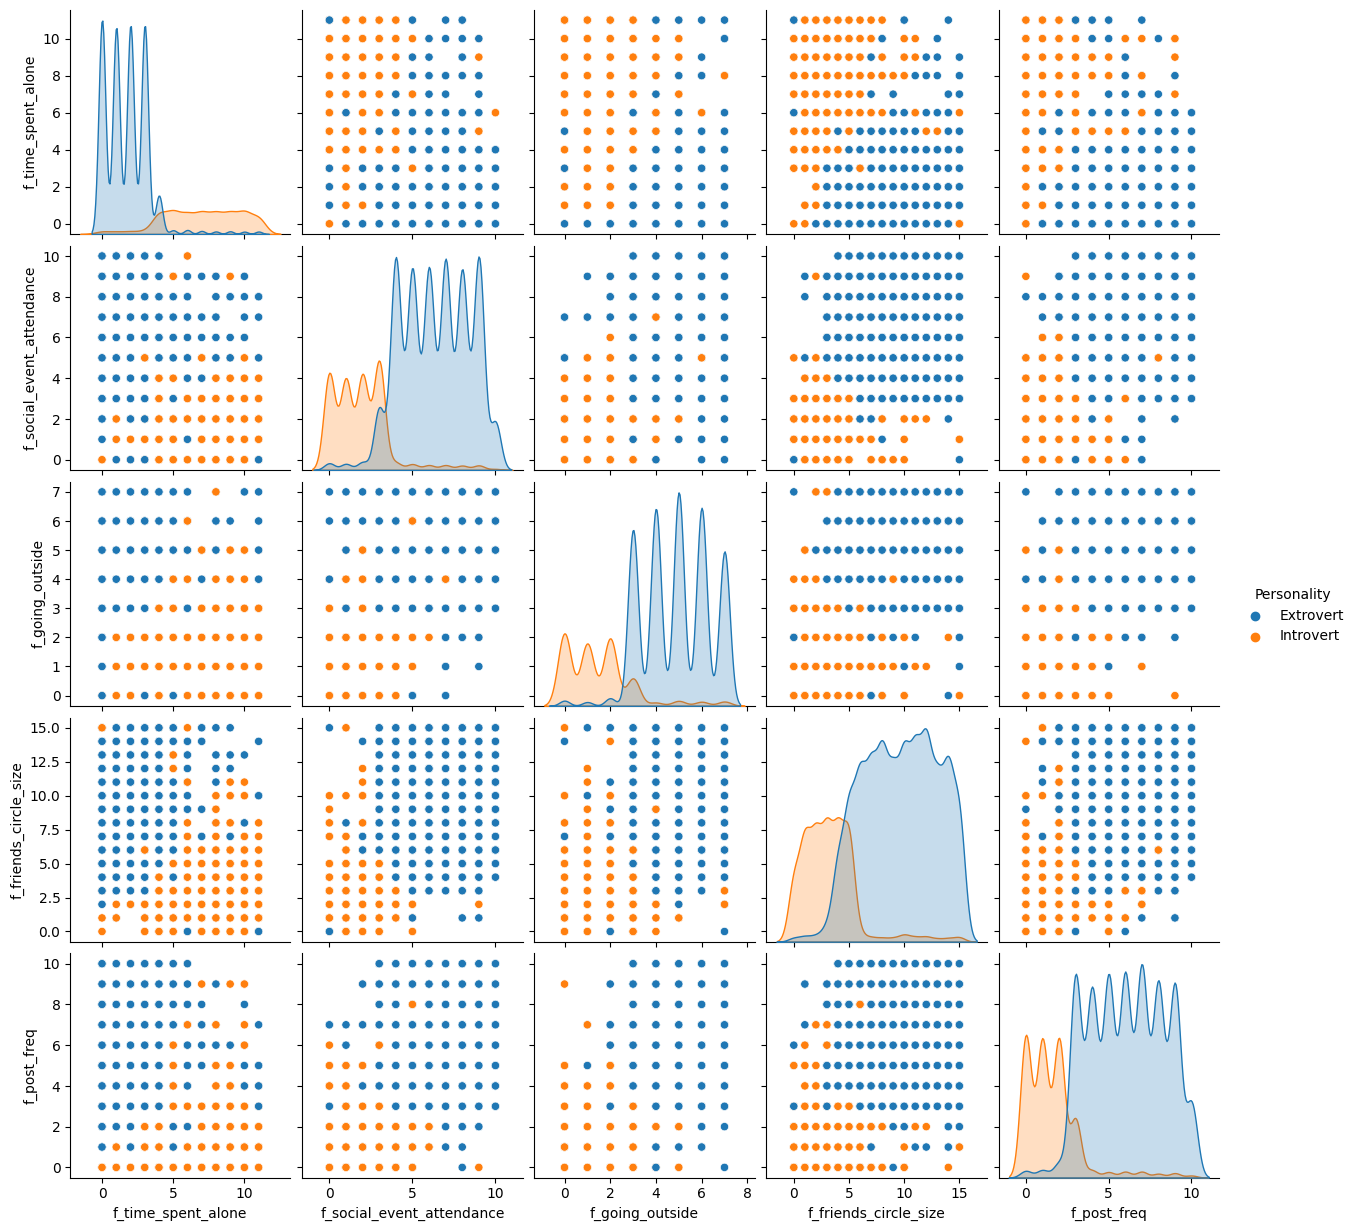

In [10]:
import warnings
warnings.filterwarnings('ignore')

d_f = d.filter(regex="^f_|Per")
graph_cols = ['f_time_spent_alone', 'f_social_event_attendance',
       'f_going_outside', 'f_friends_circle_size', 'f_post_freq']
sns.pairplot(d_f, vars=graph_cols, hue='Personality')

In [11]:
# evaluating the percent of missing rows by personality to answer the following question:
# do introverts have more missing data than extroverts?

from pandasql import sqldf

d_mis_pers = d_f[d_f.isna().any(axis=1)]
d_mis = pd.DataFrame(d_mis_pers['Personality'].value_counts())
d_f_pers = pd.DataFrame(d_f['Personality'].value_counts())

q = 'select dm.Personality, dm.count as num_missing, df.count as num_rows from d_mis as dm left join d_f_pers as df on dm.Personality = df.Personality'

miss_eval = sqldf(q)
miss_eval['perc_missing'] = miss_eval['num_missing'] / miss_eval['num_rows']
miss_eval

,Personality,num_missing,num_rows,perc_missing
0,Extrovert,3104,11002,0.282131
1,Introvert,1470,3817,0.385119


Between differnet measures, I do not see any relationships that would worry me:
* fan shaped patterns
* strong linear relationships
* clusters of data
* strong separation or stripes in data
* strong outliers

For individual field distributions, I notice the following:
 * Time spent alone may be best modeled by an exponential equation 
 * Friends circle size may be best modeled by a quadratic equation 
 * Post frequency may be best represented by quadratic equation

Non-transformed, linear equations may work well for the other fields. If the RMSE is too large for any given field, I will consider further transformations. 

Overall, I notice relatively clear divisions between a given variable and the resulting Personality category, highlighting the importance of non-mean imputation. There are more Extroverts in the dataset, meaning that the mean of a given continuous variable will favor Extroverts.   

Lastly, Introverts are more likely to have missing data. Of all rows associated to an intorvert, about 39% of those rows contain missing data. This is higher than the percentage of Extrovert rows containing missing data, 28%. 

### Beginning the process of imputing continuous values

Starting with Time Spent Alone (TSA)

In [12]:
# data for imputations
d_missing_prep = d.filter(regex="^d_|f_")
d_missing_prep = d_missing_prep.dropna()
d_missing_prep.columns

Index(['d_stage_fear_yes', 'd_stage_fear_no', 'd_stage_fear_decline',
       'd_drained_after_socializing_yes', 'd_drained_after_socializing_no',
       'd_drained_after_socializing_decline', 'f_time_spent_alone',
       'f_social_event_attendance', 'f_going_outside', 'f_friends_circle_size',
       'f_post_freq'],
      dtype='object')

Beginning with Time Spent Alone. I will first evaluate any multicolinearity issues before building a linear regression model. 

I will evaluate the multicolinearity of each dataframe, then remove any problematic VIF scores. I will repeat this process until all VIF scores are less than 5.

This is the link I used to reference VIF packages: https://www.statology.org/how-to-calculate-vif-in-python/

In [13]:
# time spent alone (tsa)
tsa_drop_cols = ['f_time_spent_alone', 'd_stage_fear_no',
       'd_drained_after_socializing_no']
d_tsa_x = d_missing_prep.drop(columns=tsa_drop_cols)
d_tsa_y = d_missing_prep['f_time_spent_alone']

out = f"the shape of predictors is: {d_tsa_x.shape}\nthe shape of predicted value is {d_tsa_y.shape}"
print(out)

the shape of predictors is: (10245, 8)
the shape of predicted value is (10245,)


In [14]:
# compute VIF to determine multicollinearity

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_tsa_x.values, i) for i in range(d_tsa_x.shape[1])]
vif['variable'] = d_tsa_x.columns
vif

,VIF,variable
0,4.064747,d_stage_fear_yes
1,1.499037,d_stage_fear_decline
2,3.823080,d_drained_after_socializing_yes
3,1.624086,d_drained_after_socializing_decline
4,8.476162,f_social_event_attendance
5,8.736556,f_going_outside
6,7.543729,f_friends_circle_size
7,7.186759,f_post_freq


In [15]:
d_tsa_x = d_tsa_x.drop(columns=['f_going_outside'])
tsa_drop_cols.append('f_going_outside')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_tsa_x.values, i) for i in range(d_tsa_x.shape[1])]
vif['variable'] = d_tsa_x.columns
vif

,VIF,variable
0,4.064394,d_stage_fear_yes
1,1.498856,d_stage_fear_decline
2,3.822311,d_drained_after_socializing_yes
3,1.624078,d_drained_after_socializing_decline
4,7.340469,f_social_event_attendance
5,6.785975,f_friends_circle_size
6,6.301681,f_post_freq


In [16]:
d_tsa_x = d_tsa_x.drop(columns=['f_social_event_attendance'])
tsa_drop_cols.append('f_social_event_attendance')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_tsa_x.values, i) for i in range(d_tsa_x.shape[1])]
vif['variable'] = d_tsa_x.columns
vif

,VIF,variable
0,4.064202,d_stage_fear_yes
1,1.496106,d_stage_fear_decline
2,3.822088,d_drained_after_socializing_yes
3,1.623604,d_drained_after_socializing_decline
4,4.968879,f_friends_circle_size
5,4.806216,f_post_freq


In [17]:
d_tsa_x = d_tsa_x.drop(columns=['f_friends_circle_size'])
tsa_drop_cols.append('f_friends_circle_size')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_tsa_x.values, i) for i in range(d_tsa_x.shape[1])]
vif['variable'] = d_tsa_x.columns
vif

,VIF,variable
0,4.057202,d_stage_fear_yes
1,1.468123,d_stage_fear_decline
2,3.821586,d_drained_after_socializing_yes
3,1.620237,d_drained_after_socializing_decline
4,1.097237,f_post_freq


In [18]:
# log f_post_freq to accomodate for exponential outcome variable

d_tsa_x['f_post_freq'] = np.log(d_tsa_x['f_post_freq'] + 1)

In [19]:
# creating linear regression model to predict TSA
d_tsa_ols_train_x = d_tsa_x.sample(frac=.8, random_state=19)
d_tsa_ols_test_x = d_tsa_x.drop(d_tsa_ols_train_x.index)

d_tsa_ols_train_x = d_tsa_ols_train_x.sort_index()

d_tsa_ols_test_y = d_tsa_y.drop(d_tsa_ols_train_x.index)
d_tsa_ols_train_y = d_tsa_y.drop(d_tsa_ols_test_y.index)

d_tsa_ols_train_x = sm.add_constant(d_tsa_ols_train_x)
d_tsa_ols_test_x = sm.add_constant(d_tsa_ols_test_x)

model_tsa = sm.OLS(d_tsa_ols_train_y, d_tsa_ols_train_x).fit()

print(model_tsa.summary())

                            OLS Regression Results                            
Dep. Variable:     f_time_spent_alone   R-squared:                       0.623
Model:                            OLS   Adj. R-squared:                  0.623
Method:                 Least Squares   F-statistic:                     2710.
Date:                Tue, 29 Jul 2025   Prob (F-statistic):               0.00
Time:                        23:45:46   Log-Likelihood:                -16270.
No. Observations:                8196   AIC:                         3.255e+04
Df Residuals:                    8190   BIC:                         3.259e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
co

In [20]:
print(f"RMSE: {np.sqrt(model_tsa.mse_model)}")

RMSE: 91.72803901132394


In [21]:
# imputing missing values and evaluating the fit

tsa_test = pd.DataFrame(round(model_tsa.predict(d_tsa_ols_test_x)), columns=['preds'])
tsa_test_results = pd.concat([tsa_test, d_tsa_ols_test_y], axis=1)
tsa_test_results['difference_preds'] = np.abs(tsa_test_results['f_time_spent_alone'] - tsa_test_results['preds'])
tsa_test_results['mean'] = round(np.mean(d_tsa_ols_train_y))
tsa_test_results['median'] = round(np.median(d_tsa_ols_train_y))
tsa_test_results['difference_mean'] = np.abs(tsa_test_results['f_time_spent_alone'] - tsa_test_results['mean'])
tsa_test_results['difference_median'] = np.abs(tsa_test_results['f_time_spent_alone'] - tsa_test_results['median'])

<Axes: xlabel='difference_preds', ylabel='Count'>

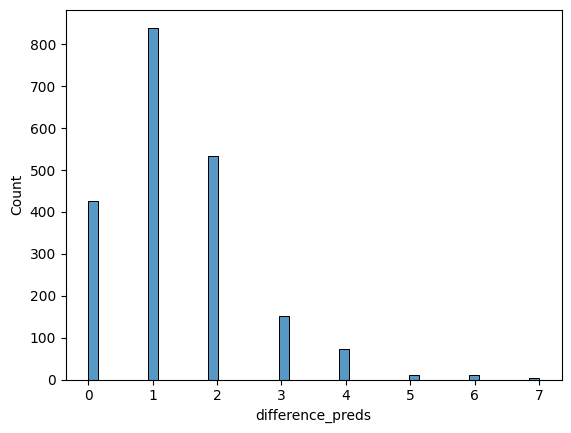

In [22]:
sns.histplot(tsa_test_results['difference_preds'])

In [23]:
out = f"Mean imputation: The difference between the mean and the true value is: {round(np.mean(tsa_test_results['difference_mean']), 2)}\n"
out += f"Median imputation: The difference between the median and the true value is: {round(np.mean(tsa_test_results['difference_median']), 2)}\n"
out += f"Log regression Imputation: The difference between the predicted and true value is: {round(np.mean(tsa_test_results['difference_preds']), 2)}\n"
print(out)

Mean imputation: The difference between the mean and the true value is: 2.21
Median imputation: The difference between the median and the true value is: 2.13
Log regression Imputation: The difference between the predicted and true value is: 1.37



I am satisfied with the performance of the TSA imputation model, so I will fill the datase with OLS imputed TSA values

In [24]:
# removing columns with multiple missing values
# then log transforming post frequency
# lastly, creating predictions for rows with only missing TSA values
d_missing_tsa = d[d['f_time_spent_alone'].isna()]
tsa_temp = d_missing_tsa.drop(columns=['f_time_spent_alone'])
tsa_temp = tsa_temp.dropna()

d_missing_tsa = d_missing_tsa.loc[d_missing_tsa.index.intersection(tsa_temp.index)]
d_missing_tsa = d_missing_tsa.filter(regex="^d_|f_")

d_tsa_exdog = d_missing_tsa.drop(columns=tsa_drop_cols)
d_tsa_exdog['f_post_freq'] = np.log(d_tsa_exdog['f_post_freq'] + 1) 
d_tsa_exdog = sm.add_constant(d_tsa_exdog)

tsa_preds = pd.DataFrame(round(model_tsa.predict(d_tsa_exdog)), columns=['pred_tsa'])
d_missing_tsa['f_time_spent_alone'] = tsa_preds

Imputing Friends Circle Size -- quadratic

In [25]:
# friends circle size (fcs)
fcs_drop_cols = ['f_friends_circle_size', 'd_stage_fear_no', 'd_drained_after_socializing_no']
d_fcs_x = d_missing_prep.drop(columns=fcs_drop_cols)
d_fcs_y = d_missing_prep['f_friends_circle_size']

out = f"the shape of predictors is: {d_fcs_x.shape}\nthe shape of predicted value is {d_fcs_y.shape}"
print(out)

the shape of predictors is: (10245, 8)
the shape of predicted value is (10245,)


In [26]:
vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_fcs_x.values, i) for i in range(d_fcs_x.shape[1])]
vif['variable'] = d_fcs_x.columns
vif

,VIF,variable
0,4.532231,d_stage_fear_yes
1,1.530471,d_stage_fear_decline
2,4.868411,d_drained_after_socializing_yes
3,1.767889,d_drained_after_socializing_decline
4,5.029839,f_time_spent_alone
5,7.577015,f_social_event_attendance
6,7.930075,f_going_outside
7,6.772389,f_post_freq


In [27]:
d_fcs_x = d_fcs_x.drop(columns=['f_going_outside'])
fcs_drop_cols.append('f_going_outside')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_fcs_x.values, i) for i in range(d_fcs_x.shape[1])]
vif['variable'] = d_fcs_x.columns
vif

,VIF,variable
0,4.531508,d_stage_fear_yes
1,1.530456,d_stage_fear_decline
2,4.862900,d_drained_after_socializing_yes
3,1.767432,d_drained_after_socializing_decline
4,4.984748,f_time_spent_alone
5,5.557844,f_social_event_attendance
6,5.349380,f_post_freq


In [28]:
d_fcs_x = d_fcs_x.drop(columns=['f_social_event_attendance'])
fcs_drop_cols.append('f_social_event_attendance')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_fcs_x.values, i) for i in range(d_fcs_x.shape[1])]
vif['variable'] = d_fcs_x.columns
vif

,VIF,variable
0,4.526567,d_stage_fear_yes
1,1.522222,d_stage_fear_decline
2,4.819193,d_drained_after_socializing_yes
3,1.766983,d_drained_after_socializing_decline
4,4.820665,f_time_spent_alone
5,1.514265,f_post_freq


In [29]:
# sqrt f_ columns
d_fcs_x['f_time_spent_alone'] = np.sqrt(d_fcs_x['f_time_spent_alone'])
d_fcs_x['f_post_freq'] = np.sqrt(d_fcs_x['f_post_freq'])

In [30]:
d_fcs_ols_train_x = d_fcs_x.sample(frac=.8, random_state=19)
d_fcs_ols_test_x = d_fcs_x.drop(d_fcs_ols_train_x.index)

d_fcs_ols_train_x = d_fcs_ols_train_x.sort_index()

d_fcs_ols_test_y = d_fcs_y.drop(d_fcs_ols_train_x.index)
d_fcs_ols_train_y = d_fcs_y.drop(d_fcs_ols_test_y.index)

d_fcs_ols_train_x = sm.add_constant(d_fcs_ols_train_x)
d_fcs_ols_test_x = sm.add_constant(d_fcs_ols_test_x)

model_fcs = sm.OLS(d_fcs_ols_train_y, d_fcs_ols_train_x).fit()

print(model_fcs.summary())

                              OLS Regression Results                             
Dep. Variable:     f_friends_circle_size   R-squared:                       0.448
Model:                               OLS   Adj. R-squared:                  0.448
Method:                    Least Squares   F-statistic:                     1109.
Date:                   Tue, 29 Jul 2025   Prob (F-statistic):               0.00
Time:                           23:45:47   Log-Likelihood:                -20900.
No. Observations:                   8196   AIC:                         4.181e+04
Df Residuals:                       8189   BIC:                         4.186e+04
Df Model:                              6                                         
Covariance Type:               nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

In [31]:
print(f"RMSE: {np.sqrt(model_fcs.mse_model)}")

RMSE: 103.24357796001559


In [32]:
fcs_test = pd.DataFrame(round(model_fcs.predict(d_fcs_ols_test_x)), columns=['preds'])

fcs_test_results = pd.concat([fcs_test, d_fcs_ols_test_y], axis=1)
fcs_test_results['difference_preds'] = np.abs(fcs_test_results['f_friends_circle_size'] - fcs_test_results['preds'])
fcs_test_results['mean'] = round(np.mean(d_fcs_ols_train_y))
fcs_test_results['difference_mean'] = np.abs(fcs_test_results['f_friends_circle_size'] - fcs_test_results['mean'])
fcs_test_results['median'] = round(np.median(d_fcs_ols_train_y))
fcs_test_results['difference_median'] = np.abs(fcs_test_results['f_friends_circle_size'] - fcs_test_results['median'])

out = f"Mean imputation: The difference between the mean and the true value is: {round(np.mean(fcs_test_results['difference_mean']), 2)}\n"
out += f"Median imputation: The difference between the median and the true value is: {round(np.mean(fcs_test_results['difference_median']), 2)}\n"
out += f"Sqrt regression Imputation: The difference between the predicted and true value is: {round(np.mean(fcs_test_results['difference_preds']), 2)}\n"
print(out)

Mean imputation: The difference between the mean and the true value is: 3.62
Median imputation: The difference between the median and the true value is: 3.62
Sqrt regression Imputation: The difference between the predicted and true value is: 2.59



<Axes: xlabel='difference_preds', ylabel='Count'>

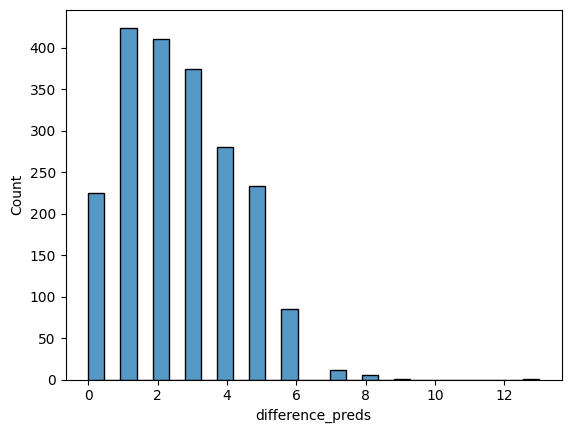

In [33]:
sns.histplot(fcs_test_results['difference_preds'])

In [34]:
# removing columns with multiple missing values
# then sqrt-ing transforming time spent alone and post frequency
# lastly, creating predictions for rows with only missing FCS values

d_missing_fcs = d[d['f_friends_circle_size'].isna()]
fcs_temp = d_missing_fcs.drop(columns=['f_friends_circle_size'])
fcs_temp = fcs_temp.dropna()

d_missing_fcs = d_missing_fcs.loc[d_missing_fcs.index.intersection(fcs_temp.index)]
d_missing_fcs = d_missing_fcs.filter(regex="^d_|f_")

d_fcs_exdog = d_missing_fcs.drop(columns=fcs_drop_cols)
d_fcs_exdog['f_time_spent_alone'] = np.sqrt(d_fcs_exdog['f_time_spent_alone'])
d_fcs_exdog['f_post_freq'] = np.sqrt(d_fcs_exdog['f_post_freq'])
d_fcs_exdog = sm.add_constant(d_fcs_exdog)

fcs_preds = pd.DataFrame(round(model_fcs.predict(d_fcs_exdog)), columns=['pred_fcs'])
d_missing_fcs['f_friends_circle_size'] = fcs_preds

Imputing Post Frequency (pf) -- Quadratic

In [35]:
pf_drop_cols = ['f_post_freq', 'd_stage_fear_no', 'd_drained_after_socializing_no']
d_pf_x = d_missing_prep.drop(columns=pf_drop_cols)
d_pf_y = d_missing_prep['f_post_freq']

out = f"the shape of predictors is: {d_pf_x.shape}\nthe shape of predicted value is {d_pf_y.shape}"
print(out)

the shape of predictors is: (10245, 8)
the shape of predicted value is (10245,)


In [36]:
vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_pf_x.values, i) for i in range(d_pf_x.shape[1])]
vif['variable'] = d_pf_x.columns
vif

,VIF,variable
0,4.529289,d_stage_fear_yes
1,1.539817,d_stage_fear_decline
2,4.869398,d_drained_after_socializing_yes
3,1.767011,d_drained_after_socializing_decline
4,5.030610,f_time_spent_alone
5,7.813560,f_social_event_attendance
6,7.733598,f_going_outside
7,7.109867,f_friends_circle_size


In [37]:
d_pf_x = d_pf_x.drop(columns=['f_social_event_attendance'])
pf_drop_cols.append('f_social_event_attendance')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_pf_x.values, i) for i in range(d_pf_x.shape[1])]
vif['variable'] = d_pf_x.columns
vif

,VIF,variable
0,4.524340,d_stage_fear_yes
1,1.539098,d_stage_fear_decline
2,4.851694,d_drained_after_socializing_yes
3,1.766484,d_drained_after_socializing_decline
4,4.978913,f_time_spent_alone
5,5.719098,f_going_outside
6,5.747656,f_friends_circle_size


In [38]:
d_pf_x = d_pf_x.drop(columns=['f_friends_circle_size'])
pf_drop_cols.append('f_friends_circle_size')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_pf_x.values, i) for i in range(d_pf_x.shape[1])]
vif['variable'] = d_pf_x.columns
vif

,VIF,variable
0,4.523603,d_stage_fear_yes
1,1.524342,d_stage_fear_decline
2,4.824480,d_drained_after_socializing_yes
3,1.766480,d_drained_after_socializing_decline
4,4.904738,f_time_spent_alone
5,1.560146,f_going_outside


In [39]:
# sqrt f_ columns
d_pf_x['f_time_spent_alone'] = np.sqrt(d_pf_x['f_time_spent_alone'])
d_pf_x['f_going_outside'] = np.sqrt(d_pf_x['f_going_outside'])

In [40]:
d_pf_ols_train_x = d_pf_x.sample(frac=.8, random_state=19)
d_pf_ols_test_x = d_pf_x.drop(d_pf_ols_train_x.index)

d_pf_ols_train_x = d_pf_ols_train_x.sort_index()

d_pf_ols_test_y = d_pf_y.drop(d_pf_ols_train_x.index)
d_pf_ols_train_y = d_pf_y.drop(d_pf_ols_test_y.index)

d_pf_ols_train_x = sm.add_constant(d_pf_ols_train_x)
d_pf_ols_test_x = sm.add_constant(d_pf_ols_test_x)

model_pf = sm.OLS(d_pf_ols_train_y, d_pf_ols_train_x).fit()

print(model_pf.summary())

                            OLS Regression Results                            
Dep. Variable:            f_post_freq   R-squared:                       0.485
Model:                            OLS   Adj. R-squared:                  0.485
Method:                 Least Squares   F-statistic:                     1286.
Date:                Tue, 29 Jul 2025   Prob (F-statistic):               0.00
Time:                        23:45:48   Log-Likelihood:                -17431.
No. Observations:                8196   AIC:                         3.488e+04
Df Residuals:                    8189   BIC:                         3.493e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
co

In [41]:
print(f"RMSE: {np.sqrt(model_pf.mse_model)}")

RMSE: 72.80570780531389


In [42]:
pf_test = pd.DataFrame(round(model_pf.predict(d_pf_ols_test_x)), columns=['preds'])

pf_test_results = pd.concat([pf_test, d_pf_ols_test_y], axis=1)
pf_test_results['difference_preds'] = np.abs(pf_test_results['f_post_freq'] - pf_test_results['preds'])
pf_test_results['mean'] = round(np.mean(d_pf_ols_train_y))
pf_test_results['difference_mean'] = np.abs(pf_test_results['f_post_freq'] - pf_test_results['mean'])
pf_test_results['median'] = round(np.median(d_pf_ols_train_y))
pf_test_results['difference_median'] = np.abs(pf_test_results['f_post_freq'] - pf_test_results['median'])

out = f"Mean imputation: The difference between the mean and the true value is: {round(np.mean(pf_test_results['difference_mean']), 2)}\n"
out += f"Median imputation: The difference between the median and the true value is: {round(np.mean(pf_test_results['difference_median']), 2)}\n"
out += f"Sqrt regression Imputation: The difference between the predicted and true value is: {round(np.mean(pf_test_results['difference_preds']), 2)}\n"
print(out)

Mean imputation: The difference between the mean and the true value is: 2.45
Median imputation: The difference between the median and the true value is: 2.45
Sqrt regression Imputation: The difference between the predicted and true value is: 1.67



<Axes: xlabel='difference_preds', ylabel='Count'>

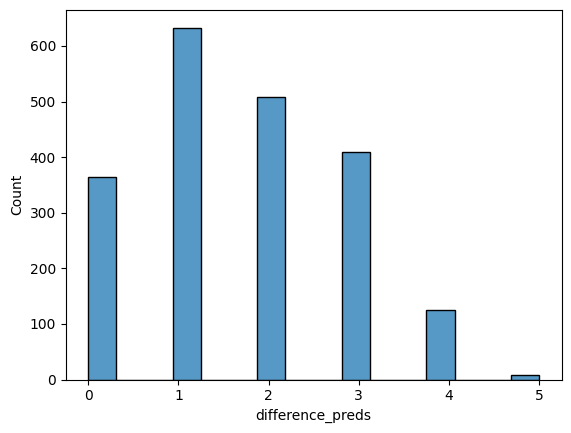

In [43]:
sns.histplot(pf_test_results['difference_preds'])

In [44]:
# removing columns with multiple missing values
# then sqrt-ing transforming time spent alone and post frequency
# lastly, creating predictions for rows with only missing PF values

d_missing_pf = d[d['f_post_freq'].isna()]
pf_temp = d_missing_pf.drop(columns=['f_post_freq'])
pf_temp = pf_temp.dropna()

d_missing_pf = d_missing_pf.loc[d_missing_pf.index.intersection(pf_temp.index)]
d_missing_pf = d_missing_pf.filter(regex="^d_|f_")

d_pf_exdog = d_missing_pf.drop(columns=pf_drop_cols)
d_pf_exdog['f_time_spent_alone'] = np.sqrt(d_pf_exdog['f_time_spent_alone'])
d_pf_exdog['f_going_outside'] = np.sqrt(d_pf_exdog['f_going_outside'])
d_pf_exdog = sm.add_constant(d_pf_exdog)

pf_preds = pd.DataFrame(round(model_pf.predict(d_pf_exdog)), columns=['pred_pf'])
d_missing_pf['f_post_freq'] = pf_preds

Imputing Social Event Attendance

In [45]:
sea_drop_cols = ['f_social_event_attendance', 'd_stage_fear_no', 'd_drained_after_socializing_no']
d_sea_x = d_missing_prep.drop(columns=sea_drop_cols)
d_sea_y = d_missing_prep['f_social_event_attendance']

out = f"the shape of predictors is: {d_sea_x.shape}\nthe shape of predicted value is {d_sea_y.shape}"
print(out)

the shape of predictors is: (10245, 8)
the shape of predicted value is (10245,)


In [46]:
vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_sea_x.values, i) for i in range(d_sea_x.shape[1])]
vif['variable'] = d_sea_x.columns
vif

,VIF,variable
0,4.530098,d_stage_fear_yes
1,1.539892,d_stage_fear_decline
2,4.861738,d_drained_after_socializing_yes
3,1.768006,d_drained_after_socializing_decline
4,5.008415,f_time_spent_alone
5,7.660841,f_going_outside
6,6.714771,f_friends_circle_size
7,6.595723,f_post_freq


In [47]:
d_sea_x = d_sea_x.drop(columns=['f_friends_circle_size'])
sea_drop_cols.append('f_friends_circle_size')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_sea_x.values, i) for i in range(d_sea_x.shape[1])]
vif['variable'] = d_sea_x.columns
vif

,VIF,variable
0,4.530085,d_stage_fear_yes
1,1.524744,d_stage_fear_decline
2,4.848607,d_drained_after_socializing_yes
3,1.767839,d_drained_after_socializing_decline
4,4.973524,f_time_spent_alone
5,5.816818,f_going_outside
6,5.645754,f_post_freq


In [48]:
d_sea_x = d_sea_x.drop(columns=['f_going_outside'])
sea_drop_cols.append('f_going_outside')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_sea_x.values, i) for i in range(d_sea_x.shape[1])]
vif['variable'] = d_sea_x.columns
vif

,VIF,variable
0,4.526567,d_stage_fear_yes
1,1.522222,d_stage_fear_decline
2,4.819193,d_drained_after_socializing_yes
3,1.766983,d_drained_after_socializing_decline
4,4.820665,f_time_spent_alone
5,1.514265,f_post_freq


In [49]:
d_sea_ols_train_x = d_sea_x.sample(frac=.8, random_state=19)
d_sea_ols_test_x = d_sea_x.drop(d_sea_ols_train_x.index)

d_sea_ols_train_x = d_sea_ols_train_x.sort_index()

d_sea_ols_test_y = d_sea_y.drop(d_sea_ols_train_x.index)
d_sea_ols_train_y = d_sea_y.drop(d_sea_ols_test_y.index)

d_sea_ols_train_x = sm.add_constant(d_sea_ols_train_x)
d_sea_ols_test_x = sm.add_constant(d_sea_ols_test_x)

model_sea = sm.OLS(d_sea_ols_train_y, d_sea_ols_train_x).fit()

print(model_sea.summary())

                                OLS Regression Results                               
Dep. Variable:     f_social_event_attendance   R-squared:                       0.524
Model:                                   OLS   Adj. R-squared:                  0.523
Method:                        Least Squares   F-statistic:                     1500.
Date:                       Tue, 29 Jul 2025   Prob (F-statistic):               0.00
Time:                               23:45:49   Log-Likelihood:                -16802.
No. Observations:                       8196   AIC:                         3.362e+04
Df Residuals:                           8189   BIC:                         3.367e+04
Df Model:                                  6                                         
Covariance Type:                   nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------

In [50]:
print(f"RMSE: {np.sqrt(model_sea.mse_model)}")

RMSE: 72.83111196813704


In [51]:
sea_test = pd.DataFrame(round(model_sea.predict(d_sea_ols_test_x)), columns=['preds'])

sea_test_results = pd.concat([sea_test, d_sea_ols_test_y], axis=1)
sea_test_results['difference_preds'] = np.abs(sea_test_results['f_social_event_attendance'] - sea_test_results['preds'])
sea_test_results['mean'] = round(np.mean(d_sea_ols_train_y))
sea_test_results['difference_mean'] = np.abs(sea_test_results['f_social_event_attendance'] - sea_test_results['mean'])
sea_test_results['median'] = round(np.median(d_sea_ols_train_y))
sea_test_results['difference_median'] = np.abs(sea_test_results['f_social_event_attendance'] - sea_test_results['median'])

out = f"Mean imputation: The difference between the mean and the true value is: {round(np.mean(sea_test_results['difference_mean']), 2)}\n"
out += f"Median imputation: The difference between the median and the true value is: {round(np.mean(sea_test_results['difference_median']), 2)}\n"
out += f"Linear regression Imputation: The difference between the predicted and true value is: {round(np.mean(sea_test_results['difference_preds']), 2)}\n"
print(out)

Mean imputation: The difference between the mean and the true value is: 2.29
Median imputation: The difference between the median and the true value is: 2.3
Linear regression Imputation: The difference between the predicted and true value is: 1.58



<Axes: xlabel='difference_preds', ylabel='Count'>

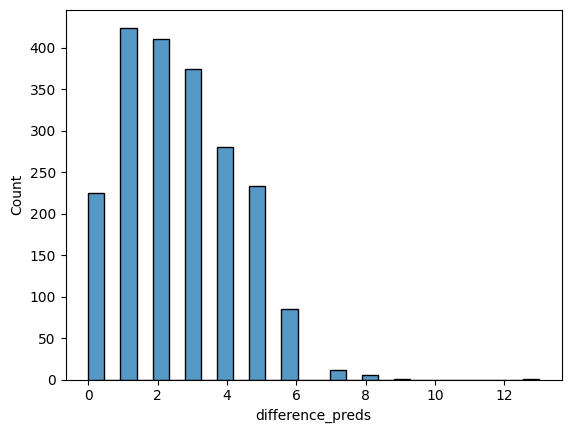

In [52]:
sns.histplot(fcs_test_results['difference_preds'])

In [53]:
d_missing_sea = d[d['f_social_event_attendance'].isna()]
sea_temp = d_missing_sea.drop(columns=['f_social_event_attendance'])
sea_temp = sea_temp.dropna()

d_missing_sea = d_missing_sea.loc[d_missing_sea.index.intersection(sea_temp.index)]
d_missing_sea = d_missing_sea.filter(regex="^d_|f_")

d_sea_exdog = d_missing_sea.drop(columns=sea_drop_cols)
d_sea_exdog = sm.add_constant(d_sea_exdog)

sea_preds = pd.DataFrame(round(model_sea.predict(d_sea_exdog)), columns=['pred_sea'])
d_missing_sea['f_social_event_attendance'] = sea_preds

Imputing Going Outside

In [54]:
# going outside (go)
go_drop_cols = ['f_going_outside', 'd_stage_fear_no', 'd_drained_after_socializing_no']
d_go_x = d_missing_prep.drop(columns=go_drop_cols)
d_go_y = d_missing_prep['f_going_outside']

out = f"the shape of predictors is: {d_go_x.shape}\nthe shape of predicted value is {d_go_y.shape}"
print(out)

the shape of predictors is: (10245, 8)
the shape of predicted value is (10245,)


In [55]:
vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_go_x.values, i) for i in range(d_go_x.shape[1])]
vif['variable'] = d_go_x.columns
vif

,VIF,variable
0,4.531628,d_stage_fear_yes
1,1.540411,d_stage_fear_decline
2,4.871212,d_drained_after_socializing_yes
3,1.767509,d_drained_after_socializing_decline
4,5.015177,f_time_spent_alone
5,7.442543,f_social_event_attendance
6,6.827399,f_friends_circle_size
7,6.342200,f_post_freq


In [56]:
d_go_x = d_go_x.drop(columns=['f_social_event_attendance'])
go_drop_cols.append('f_social_event_attendance')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_go_x.values, i) for i in range(d_go_x.shape[1])]
vif['variable'] = d_go_x.columns
vif

,VIF,variable
0,4.527237,d_stage_fear_yes
1,1.539616,d_stage_fear_decline
2,4.853047,d_drained_after_socializing_yes
3,1.766992,d_drained_after_socializing_decline
4,4.946394,f_time_spent_alone
5,5.098474,f_friends_circle_size
6,4.923948,f_post_freq


In [57]:
d_go_x = d_go_x.drop(columns=['f_friends_circle_size'])
go_drop_cols.append('f_friends_circle_size')

vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(d_go_x.values, i) for i in range(d_go_x.shape[1])]
vif['variable'] = d_go_x.columns
vif

,VIF,variable
0,4.526567,d_stage_fear_yes
1,1.522222,d_stage_fear_decline
2,4.819193,d_drained_after_socializing_yes
3,1.766983,d_drained_after_socializing_decline
4,4.820665,f_time_spent_alone
5,1.514265,f_post_freq


In [58]:
d_go_ols_train_x = d_go_x.sample(frac=.8, random_state=19)
d_go_ols_test_x = d_go_x.drop(d_go_ols_train_x.index)

d_go_ols_train_x = d_go_ols_train_x.sort_index()

d_go_ols_test_y = d_go_y.drop(d_go_ols_train_x.index)
d_go_ols_train_y = d_go_y.drop(d_go_ols_test_y.index)

d_go_ols_train_x = sm.add_constant(d_go_ols_train_x)
d_go_ols_test_x = sm.add_constant(d_go_ols_test_x)

model_go = sm.OLS(d_go_ols_train_y, d_go_ols_train_x).fit()

print(model_go.summary())

                            OLS Regression Results                            
Dep. Variable:        f_going_outside   R-squared:                       0.542
Model:                            OLS   Adj. R-squared:                  0.541
Method:                 Least Squares   F-statistic:                     1612.
Date:                Tue, 29 Jul 2025   Prob (F-statistic):               0.00
Time:                        23:45:51   Log-Likelihood:                -14208.
No. Observations:                8196   AIC:                         2.843e+04
Df Residuals:                    8189   BIC:                         2.848e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
co

In [59]:
print(f"RMSE: {np.sqrt(model_go.mse_model)}")

RMSE: 55.01524567929993


In [60]:
go_test = pd.DataFrame(round(model_go.predict(d_go_ols_test_x)), columns=['preds'])

go_test_results = pd.concat([go_test, d_go_ols_test_y], axis=1)
go_test_results['difference_preds'] = np.abs(go_test_results['f_going_outside'] - go_test_results['preds'])
go_test_results['mean'] = round(np.mean(d_go_ols_train_y))
go_test_results['difference_mean'] = np.abs(go_test_results['f_going_outside'] - go_test_results['mean'])
go_test_results['median'] = round(np.median(d_go_ols_train_y))
go_test_results['difference_median'] = np.abs(go_test_results['f_going_outside'] - go_test_results['median'])

out = f"Mean imputation: The difference between the mean and the true value is: {round(np.mean(go_test_results['difference_mean']), 2)}\n"
out += f"Median imputation: The difference between the median and the true value is: {round(np.mean(go_test_results['difference_median']), 2)}\n"
out += f"Linear regression Imputation: The difference between the predicted and true value is: {round(np.mean(go_test_results['difference_preds']), 2)}\n"
print(out)



Mean imputation: The difference between the mean and the true value is: 1.69
Median imputation: The difference between the median and the true value is: 1.69
Linear regression Imputation: The difference between the predicted and true value is: 1.18



In [61]:
d_missing_go = d[d['f_going_outside'].isna()]
go_temp = d_missing_go.drop(columns=['f_going_outside'])
go_temp = go_temp.dropna()

d_missing_go = d_missing_go.loc[d_missing_go.index.intersection(go_temp.index)]
d_missing_go = d_missing_go.filter(regex="^d_|f_")

d_go_exdog = d_missing_go.drop(columns=go_drop_cols)
d_go_exdog = sm.add_constant(d_go_exdog)

go_preds = pd.DataFrame(round(model_go.predict(d_go_exdog)), columns=['pred_go'])
d_missing_go['f_going_outside'] = go_preds


In [62]:
d_imputed = pd.concat(
    [d_missing_prep,
    d_missing_tsa,
    d_missing_fcs,
    d_missing_go,
    d_missing_pf, 
    d_missing_sea]
)

d_imputed = d_imputed.sort_index()
d_imputed

,d_stage_fear_yes,d_stage_fear_no,d_stage_fear_decline,d_drained_after_socializing_yes,d_drained_after_socializing_no,d_drained_after_socializing_decline,f_time_spent_alone,f_social_event_attendance,f_going_outside,f_friends_circle_size,f_post_freq
0,0,1,0,0,1,0,0.0,6.0,4.0,15.0,5.0
1,0,1,0,0,1,0,1.0,7.0,3.0,10.0,8.0
2,1,0,0,0,0,1,6.0,1.0,0.0,3.0,0.0
4,0,1,0,0,1,0,1.0,4.0,4.0,13.0,6.0
5,0,1,0,0,1,0,2.0,8.0,5.0,9.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...
18517,0,1,0,0,1,0,3.0,6.0,4.0,7.0,6.0
18518,0,0,1,0,1,0,3.0,8.0,3.0,5.0,8.0
18519,0,1,0,0,1,0,3.0,7.0,3.0,9.0,7.0
18522,1,0,0,1,0,0,7.0,1.0,0.0,5.0,2.0


Building the classification model

In [63]:
d_train_y = data['Personality'].loc[data.index.intersection(d_imputed.index)]
d_train_y = d_train_y.sort_index()

model_p_1 = LogisticRegression(random_state=19).fit(d_imputed, d_train_y)
model_p_1.score(d_imputed, d_train_y)

0.9693110647181629

Impute values with two or more missing values

In [64]:
d_test_missing_prep = d_test.dropna().filter(regex="^d_|f_")

In [65]:
# impute tsa preds for test data

# removing columns with multiple missing values
d_test_missing_tsa = d_test[d_test['f_time_spent_alone'].isna()]
t_tsa_temp = d_test_missing_tsa.drop(columns=['f_time_spent_alone', 'Time_spent_Alone'])
t_tsa_temp = t_tsa_temp.dropna()

d_test_missing_tsa = d_test_missing_tsa.loc[d_test_missing_tsa.index.intersection(t_tsa_temp.index)]
d_test_missing_tsa = d_test_missing_tsa.filter(regex="^d_|f_")

# prep exdog for model

d_test_tsa_exdog = d_test_missing_tsa.drop(columns=['d_stage_fear_no','d_drained_after_socializing_no',
    'f_time_spent_alone','f_social_event_attendance', 
    'f_going_outside', 'f_friends_circle_size'])
d_test_tsa_exdog = sm.add_constant(d_test_tsa_exdog)

t_tsa_preds = pd.DataFrame(round(model_tsa.predict(d_test_tsa_exdog)), columns=['pred_tsa'])
d_test_missing_tsa['f_time_spent_alone'] = t_tsa_preds


In [66]:
# imputing sea preds
# preparing actual predictions
# removing columns with multiple missing values

d_test_missing_sea = d_test[d_test['f_social_event_attendance'].isna()]
t_sea_temp = d_test_missing_sea.drop(columns=['f_social_event_attendance', 'Social_event_attendance'])
t_sea_temp = t_sea_temp.dropna()

d_test_missing_sea = d_test_missing_sea.loc[d_test_missing_sea.index.intersection(t_sea_temp.index)]
d_test_missing_sea = d_test_missing_sea.filter(regex="^d_|f_")

# prep exdog for model

d_test_sea_exdog = d_test_missing_sea.drop(columns=sea_drop_cols)
d_test_sea_exdog = sm.add_constant(d_test_sea_exdog)

t_sea_preds = pd.DataFrame(round(model_sea.predict(d_test_sea_exdog)), columns=['pred_sea'])
d_test_missing_sea['f_social_event_attendance'] = t_sea_preds

In [67]:
# imputing pf
# preparing actual predictions
# removing columns with multiple missing values

d_test_missing_pf = d_test[d_test['f_post_freq'].isna()]
t_pf_temp = d_test_missing_pf.drop(columns=['f_post_freq', 'Post_frequency'])
t_pf_temp = t_pf_temp.dropna()

d_test_missing_pf = d_test_missing_pf.loc[d_test_missing_pf.index.intersection(t_pf_temp.index)]
d_test_missing_pf = d_test_missing_pf.filter(regex="^d_|f_")

# prep exdog for model

d_test_pf_exdog = d_test_missing_pf.drop(columns=pf_drop_cols)
d_test_pf_exdog = sm.add_constant(d_test_pf_exdog)

t_pf_preds = pd.DataFrame(round(model_pf.predict(d_test_pf_exdog)), columns=['pred_pf'])
d_test_missing_pf['f_post_freq'] = t_pf_preds

In [68]:
# imputing go
# preparing actual predictions
# removing columns with multiple missing values

d_test_missing_go = d_test[d_test['f_going_outside'].isna()]
t_go_temp = d_test_missing_go.drop(columns=['f_going_outside', 'Going_outside'])
t_go_temp = t_go_temp.dropna()

d_test_missing_go = d_test_missing_go.loc[d_test_missing_go.index.intersection(t_go_temp.index)]
d_test_missing_go = d_test_missing_go.filter(regex="^d_|f_")

# prep exdog for model

d_test_go_exdog = d_test_missing_go.drop(columns=go_drop_cols)
d_test_go_exdog = sm.add_constant(d_test_go_exdog)

t_go_preds = pd.DataFrame(round(model_go.predict(d_test_go_exdog)), columns=['pred_go'])
d_test_missing_go['f_going_outside'] = t_go_preds


In [69]:
# imputing fcs
# preparing actual predictions
# removing columns with multiple missing values

d_test_missing_fcs = d_test[d_test['f_friends_circle_size'].isna()]
t_fcs_temp = d_test_missing_fcs.drop(columns=['f_friends_circle_size', 'Friends_circle_size'])
t_fcs_temp = t_fcs_temp.dropna()

d_test_missing_fcs = d_test_missing_fcs.loc[d_test_missing_fcs.index.intersection(t_fcs_temp.index)]
d_test_missing_fcs = d_test_missing_fcs.filter(regex="^d_|f_")

# prep exdog for model

d_test_fcs_exdog = d_test_missing_fcs.drop(columns=fcs_drop_cols)
d_test_fcs_exdog = sm.add_constant(d_test_fcs_exdog)

t_fcs_preds = pd.DataFrame(round(model_fcs.predict(d_test_fcs_exdog)), columns=['pred_fcs'])
d_test_missing_fcs['f_friends_circle_size'] = t_fcs_preds

In [70]:
# impute test values
# make testing vector

d_test_imputed = pd.concat(
    [d_test_missing_prep,
    d_test_missing_tsa,
    d_test_missing_fcs,
    d_test_missing_go,
    d_test_missing_pf, 
    d_test_missing_sea]
)

d_test_imputed = d_test_imputed.sort_index()

d_test_y = d_test['Personality'].loc[d_test.index.intersection(d_test_imputed.index)]
d_test_y = d_test_y.sort_index()

model_p_1.score(d_test_imputed, d_test_y)

0.9652986319652986

Now time to make the submisison data

In [71]:
S_DATA = pd.read_csv(os.path.join(c['dir'], c['test']))
s_data = S_DATA.copy()

In [72]:
# then transform stage fear and drained after socializing into flags
# d_ prefix to notate a categorical / dimensional column
s_data['d_stage_fear_yes'] = np.where(s_data['Stage_fear'] == 'Yes', 1, 0)
s_data['d_stage_fear_no'] = np.where(s_data['Stage_fear'] == 'No', 1, 0)
s_data['d_stage_fear_decline'] = np.where(s_data['Stage_fear'].isna(), 1, 0)

s_data['d_drained_after_socializing_yes'] = np.where(s_data['Drained_after_socializing'] == 'Yes', 1, 0)
s_data['d_drained_after_socializing_no'] = np.where(s_data['Drained_after_socializing'] == 'No', 1, 0)
s_data['d_drained_after_socializing_decline'] = np.where(s_data['Drained_after_socializing'].isna(), 1, 0)

# prepare measures with new column names f_ 
s_data['f_time_spent_alone'] = s_data['Time_spent_Alone']
s_data['f_social_event_attendance'] = s_data['Social_event_attendance']
s_data['f_going_outside'] = s_data['Going_outside']
s_data['f_friends_circle_size'] = s_data['Friends_circle_size']
s_data['f_post_freq'] = s_data['Post_frequency']

# create working copy of dataset
s_d = s_data.filter(regex="^d_|f_")

In [73]:
s_missing_prep = s_d.dropna()

In [74]:
# impute tsa preds for test data

# removing columns with multiple missing values
s_missing_tsa = s_d[s_d['f_time_spent_alone'].isna()]
s_tsa_temp = s_missing_tsa.drop(columns=['f_time_spent_alone'])
s_tsa_temp = s_tsa_temp.dropna()

s_missing_tsa = s_missing_tsa.loc[s_missing_tsa.index.intersection(s_tsa_temp.index)]
s_missing_tsa = s_missing_tsa.filter(regex="^d_|f_")

# prep exdog for model
s_tsa_exdog = s_missing_tsa.drop(columns=tsa_drop_cols)
s_tsa_exdog = sm.add_constant(s_tsa_exdog)

s_tsa_preds = pd.DataFrame(round(model_tsa.predict(s_tsa_exdog)), columns=['pred_tsa'])
s_missing_tsa['f_time_spent_alone'] = s_tsa_preds


# imputing sea preds

s_missing_sea = s_d[s_d['f_social_event_attendance'].isna()]
s_sea_temp = s_missing_sea.drop(columns=['f_social_event_attendance'])
s_sea_temp = s_sea_temp.dropna()

s_missing_sea = s_missing_sea.loc[s_missing_sea.index.intersection(s_sea_temp.index)]
s_missing_sea = s_missing_sea.filter(regex="^d_|f_")

# prep exdog for model
s_sea_exdog = s_missing_sea.drop(columns=sea_drop_cols)
s_sea_exdog = sm.add_constant(s_sea_exdog)

s_sea_preds = pd.DataFrame(round(model_sea.predict(s_sea_exdog)), columns=['pred_sea'])
s_missing_sea['f_social_event_attendance'] = s_sea_preds


# imputing pf
s_missing_pf = s_d[s_d['f_post_freq'].isna()]
s_pf_temp = s_missing_pf.drop(columns=['f_post_freq'])
s_pf_temp = s_pf_temp.dropna()

s_missing_pf = s_missing_pf.loc[s_missing_pf.index.intersection(s_pf_temp.index)]
s_missing_pf = s_missing_pf.filter(regex="^d_|f_")

# prep exdog for model

s_pf_exdog = s_missing_pf.drop(columns=pf_drop_cols)
s_pf_exdog = sm.add_constant(s_pf_exdog)

s_pf_preds = pd.DataFrame(round(model_pf.predict(s_pf_exdog)), columns=['pred_pf'])
s_missing_pf['f_post_freq'] = s_pf_preds


# imputing go

s_missing_go = s_d[s_d['f_going_outside'].isna()]
s_go_temp = s_missing_go.drop(columns=['f_going_outside'])
s_go_temp = s_go_temp.dropna()

s_missing_go = s_missing_go.loc[s_missing_go.index.intersection(s_go_temp.index)]
s_missing_go = s_missing_go.filter(regex="^d_|f_")

# prep exdog for model

s_go_exdog = s_missing_go.drop(columns=go_drop_cols)
s_go_exdog = sm.add_constant(s_go_exdog)

s_go_preds = pd.DataFrame(round(model_go.predict(s_go_exdog)), columns=['pred_go'])
s_missing_go['f_going_outside'] = s_go_preds


# imputing fcs

s_missing_fcs = s_d[s_d['f_friends_circle_size'].isna()]
s_fcs_temp = s_missing_fcs.drop(columns=['f_friends_circle_size'])
s_fcs_temp = s_fcs_temp.dropna()

s_missing_fcs = s_missing_fcs.loc[s_missing_fcs.index.intersection(s_fcs_temp.index)]
s_missing_fcs = s_missing_fcs.filter(regex="^d_|f_")

# prep exdog for model

s_fcs_exdog = s_missing_fcs.drop(columns=fcs_drop_cols)
s_fcs_exdog = sm.add_constant(s_fcs_exdog)

s_fcs_preds = pd.DataFrame(round(model_fcs.predict(s_fcs_exdog)), columns=['pred_fcs'])
s_missing_fcs['f_friends_circle_size'] = s_fcs_preds

In [75]:
# impute for test values

s_imputed = pd.concat(
    [s_missing_prep,
    s_missing_tsa,
    s_missing_fcs,
    s_missing_go,
    s_missing_pf, 
    s_missing_sea]
)

s_imputed = s_imputed.sort_index()

In [76]:
# imputing values for rows with multiple missing values
s_multi_na = s_d.drop(index=s_imputed.index)

s_tsa_pf = s_multi_na[s_multi_na['f_time_spent_alone'].isna() & s_multi_na['f_post_freq'].isna()] 
s_tsa_pf_temp = s_multi_na.drop(index=s_tsa_pf.index)

s_tsa_pf['f_time_spent_alone'] = round(np.median(d_tsa_ols_test_x))
s_tsa_pf['f_post_freq'] = round(np.median(d_pf_ols_test_x))
s_tsa_pf['f_social_event_attendance'][s_tsa_pf['f_social_event_attendance'].isna()] = round(np.median(d_sea_ols_test_x))

# reunite the missing values dset
s_multi_na = pd.concat(
    [s_tsa_pf, 
     s_tsa_pf_temp]
)

In [77]:
# predicting tsa values without missing pf values

s_tsa_multi = s_multi_na[s_multi_na['f_time_spent_alone'].isna() & ~s_multi_na['f_post_freq'].isna()]
s_tsa_temp = s_multi_na.drop(s_tsa_multi.index)

s_tsa_exdog_2 = s_tsa_multi.drop(columns=['d_stage_fear_no','d_drained_after_socializing_no',
    'f_time_spent_alone','f_social_event_attendance', 
    'f_going_outside', 'f_friends_circle_size'])
s_tsa_exdog_2 = sm.add_constant(s_tsa_exdog_2)
# d_tsa_exdog

s_tsa_preds = pd.DataFrame(round(model_tsa.predict(s_tsa_exdog_2)), columns=['pred_tsa'])
s_tsa_multi['f_time_spent_alone'] = s_tsa_preds

# reunite the missing values dset
s_multi_na = pd.concat(
    [s_tsa_multi, 
     s_tsa_temp]
)

In [78]:
# now predict pf becasue all of tsa is imputed
# prep exdog for model

s_pf_multi = s_multi_na[s_multi_na['f_post_freq'].isna()]
s_pf_temp = s_multi_na.drop(s_pf_multi.index)

s_pf_exdog_2 = s_pf_multi.drop(columns=pf_drop_cols)
s_pf_exdog_2 = sm.add_constant(s_pf_exdog_2)

# since all pf values in this case are dependent on a predictor, going outside, I am going to perform median imputation
s_pf_multi['f_post_freq'] = round(np.median(d_pf_ols_test_x))

s_multi_na = pd.concat(
    [s_pf_multi,
     s_pf_temp]
)

In [79]:
# now predict go because go is dependent on tsa and pf

s_go_multi = s_multi_na[s_multi_na['f_going_outside'].isna()]
s_go_temp = s_multi_na.drop(s_go_multi.index)

# prep exdog for model

s_go_exdog_2 = s_go_multi.drop(columns=go_drop_cols)
s_go_exdog_2 = sm.add_constant(s_go_exdog_2)

s_go_preds = pd.DataFrame(round(model_go.predict(s_go_exdog_2)), columns=['pred_go'])
s_go_multi['f_going_outside'] = s_go_preds

# reunite dsets
s_multi_na = pd.concat(
    [s_go_multi,
     s_go_temp]
)

In [80]:
# now predict sea because tsa and pf have been imputed
s_sea_multi = s_multi_na[s_multi_na['f_social_event_attendance'].isna()]
s_sea_temp = s_multi_na.drop(s_sea_multi.index)

# prep exdog for model

s_sea_exdog_2 = s_sea_multi.drop(columns=sea_drop_cols)
s_sea_exdog_2 = sm.add_constant(s_sea_exdog_2)

s_sea_preds = pd.DataFrame(round(model_sea.predict(s_sea_exdog_2)), columns=['pred_sea'])
s_sea_multi['f_social_event_attendance'] = s_sea_preds

# reunite dsets
s_multi_na = pd.concat(
    [s_sea_multi,
     s_sea_temp]
)

In [81]:
# now predict fcs because tsa and pf have been imputed
s_fcs_multi = s_multi_na[s_multi_na['f_friends_circle_size'].isna()]
s_fcs_temp = s_multi_na.drop(s_fcs_multi.index)

# prep exdog for model

s_fcs_exdog_2 = s_fcs_multi.drop(columns=fcs_drop_cols)
s_fcs_exdog_2 = sm.add_constant(s_fcs_exdog_2)

s_fcs_preds = pd.DataFrame(round(model_fcs.predict(s_fcs_exdog_2)), columns=['pred_fcs'])
s_fcs_multi['f_friends_circle_size'] = s_fcs_preds

# reunite dsets
s_multi_na = pd.concat(
    [s_fcs_multi,
     s_fcs_temp]
)

In [82]:
# unite full dataset
s_full = pd.concat(
    [s_imputed,
    s_multi_na]
)

s_full = s_full.sort_index()

not_missing = s_full.dropna()
still_missing = s_full.drop(index=not_missing.index)

out = f"The shape of not missing data is: {not_missing.shape}"
out += f"\nThe num. rows that still have missing data: {still_missing.shape[0]}"
print(out)


The shape of not missing data is: (6175, 11)
The num. rows that still have missing data: 0


Preparing predictions

In [83]:
final_results = pd.DataFrame(s_data["id"], columns=["id"])
final_results["Personality"] = model_p_1.predict(s_full)
out = f"The shape of the final output is: {final_results.shape}"
print(out)

The shape of the final output is: (6175, 2)


In [84]:
final_results.head(10)

,id,Personality
0,18524,Extrovert
1,18525,Introvert
2,18526,Extrovert
3,18527,Extrovert
4,18528,Introvert
5,18529,Extrovert
6,18530,Extrovert
7,18531,Introvert
8,18532,Extrovert
9,18533,Introvert


In [85]:
final_results.to_csv(os.path.join(c['out_dir'], c['out']), index=False)